# Прогнозирование стоимости автомобилей для AutoValue AI

# Описание проекта

AutoValue AI — стартап, развивающий сервис мгновенного выкупа автомобилей с пробегом. Компания стремится полностью автоматизировать процесс оценки стоимости автомобиля: после заполнения анкеты клиентом модель машинного обучения должна за считанные секунды определить справедливую цену выкупа.

До настоящего момента оценка выполнялась вручную экспертами, что ограничивает скорость обработки заявок, масштабируемость бизнеса и приводит к влиянию человеческого фактора. Для перехода к автоматизированной системе компания накопила исторические данные о ранее проведённых сделках, которые могут быть использованы для обучения модели машинного обучения.

В рамках проекта необходимо провести сравнительный анализ трёх популярных библиотек градиентного бустинга — CatBoost, LightGBM и XGBoost — определить наиболее эффективную модель и оценить её не только с точки зрения классических метрик качества, но и с позиции бизнес-рисков компании.

# Цель проекта

Разработать модель машинного обучения для прогнозирования рыночной стоимости автомобилей на основе исторических данных и выбрать библиотеку градиентного бустинга, обеспечивающую наилучшее сочетание качества предсказаний и бизнес-эффективности.

# Описание данных

`brand` - 	Марка автомобиля (Фундамент цены: престиж и надёжность бренда.)

`make_year`	- Год выпуска (Главный счётчик амортизации: чем старше автомобиль, тем дешевле.)

`mileage_kmpl` - Пробег (км) (Реальный физический износ автомобиля.)

`engine_cc` - Объём двигателя (в кубических см)	(Влияет на мощность, налоги и интерес покупателей.)

`fuel_type` - Тип топлива (Экономичность против мощности. Важный фактор ликвидности.)

`transmission` - Тип коробки передач («Автомат» или «механика» — ключевой фактор комфорта.)

`owner_count` - Количество владельцев по ПТС (Юридическая чистота и аккуратность эксплуатации.)

`color` - Цвет автомобиля (Психологический фактор: популярные цвета продаются быстрее.)

`service_history` - Наличие сервисной книжки (Подтверждает, что за машиной ухаживали вовремя.)

`accidents_reported` - Количество зафиксированных ДТП (Сильно бьёт по цене и безопасности будущей сделки.)

`insurance_valid` - Действительна ли страховка (Снижает первичные расходы покупателя после сделки.)

`region` - Макрорегион РФ, в котором продаётся автомобиль (Москва, Сибирь, Юг) (Позволяет модели учитывать региональную специфику цен.)

# Целевая переменная

`price_rub` - Целевой признак: рыночная стоимость автомобиля в рублях (Реальная сумма сделки, которую нужно предсказать.)


# Подготовка окружения

Импорт библиотек, используемых для анализа данных, обучения моделей и оценки результатов.

In [1]:
#import sys

#!{sys.executable} -m pip install -q phik
#!{sys.executable} -m pip install -q optuna
#!{sys.executable} -m pip install -q shap
#!{sys.executable} -m pip install -q --upgrade xgboost

!pip install -U "xgboost>=1.7.0" -q
!pip install -U "catboost>=1.2" -q
!pip install -U "lightgbm>=4.0.0" -q
!pip install -U "optuna>=3.0.0" -q
!pip install -U "shap>=0.42.0" -q
!pip install -U "phik>=0.12.0" -q
!pip install -U "scikit-learn>=1.2.0" -q

In [2]:
# ==========================================

# БАЗОВЫЕ БИБЛИОТЕКИ

# ==========================================

import warnings
import time

import numpy as np
import pandas as pd
from pathlib import Path

# ==========================================

# ВИЗУАЛИЗАЦИЯ

# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
from phik import phik_matrix

sns.set_theme(style='whitegrid')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.2f}'.format)

# ==========================================

# ПОДГОТОВКА ДАННЫХ И МЕТРИКИ

# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import OneHotEncoder

from sklearn.metrics import (
mean_absolute_error,
mean_squared_error,
r2_score
)

# ==========================================

# ГРАДИЕНТНЫЙ БУСТИНГ

# ==========================================

import lightgbm as lgb
import xgboost as xgb

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


# ==========================================

# ПОДБОР ГИПЕРПАРАМЕТРОВ

# ==========================================

import optuna

# ==========================================

# ИНТЕРПРЕТАЦИЯ МОДЕЛЕЙ

# ==========================================

import shap

# ==========================================

# ДОПОЛНИТЕЛЬНО

# ==========================================

from tqdm.notebook import tqdm
from sklearn.dummy import DummyRegressor

warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [3]:
# Создаем requirements.txt

!pip freeze > requirements.txt

# 1. Исследовательский анализ данных (EDA)

Изучаем распределения целевой переменной и признаков, взаимосвязи между ними, а также сопоставимость обучающей и тестовой выборок.

In [ ]:
# Локальные пути к данным. Исходные CSV не входят в публичный репозиторий.
from pathlib import Path

DATA_DIR = Path('../data')
train = pd.read_csv(DATA_DIR / 'ds_s16_train_data.csv')
test = pd.read_csv(DATA_DIR / 'ds_s16_test_data.csv')

print(f'Размер train: {train.shape}')
print(f'Размер test: {test.shape}')


In [5]:
# Изучим первые строки датасета.

train.head()

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,brand,transmission,color,service_history,accidents_reported,insurance_valid,price_rub,region
0,2002,9.70,1800,Diesel,2,Hyundai,Manual,Silver,Partial,0,No,242073,Урал
1,2004,16.10,1500,Diesel,3,Hyundai,Manual,Black,Unknown,0,No,426029,Москва
2,2005,10.51,5000,Diesel,2,Ford,Manual,Gray,Full,0,No,727050,Юг
3,2019,14.27,2000,Petrol,5,Hyundai,Manual,White,Full,1,Yes,753168,Дальний Восток
4,2015,21.72,1000,Petrol,1,Toyota,Automatic,Black,Full,0,Yes,733390,Сибирь


In [6]:
# Получим общую информацию о признаках.

train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   make_year           8000 non-null   int64  
 1   mileage_kmpl        8000 non-null   float64
 2   engine_cc           8000 non-null   int64  
 3   fuel_type           8000 non-null   object 
 4   owner_count         8000 non-null   int64  
 5   brand               8000 non-null   object 
 6   transmission        8000 non-null   object 
 7   color               8000 non-null   object 
 8   service_history     8000 non-null   object 
 9   accidents_reported  8000 non-null   int64  
 10  insurance_valid     8000 non-null   object 
 11  price_rub           8000 non-null   int64  
 12  region              8000 non-null   object 
dtypes: float64(1), int64(5), object(7)
memory usage: 812.6+ KB


In [7]:
# Посмотрим на основные статистики числовых признаков.

train.describe().T

,count,mean,std,min,25%,50%,75%,max
make_year,"8,000.00","2,009.22",8.39,"1,995.00","2,002.00","2,009.00","2,017.00","2,023.00"
mileage_kmpl,"8,000.00",17.95,5.02,5.00,14.53,17.97,21.35,35.00
engine_cc,"8,000.00","2,289.69","1,289.81",800.00,"1,200.00","2,000.00","3,000.00","5,000.00"
owner_count,"8,000.00",3.00,1.42,1.00,2.00,3.00,4.00,5.00
accidents_reported,"8,000.00",0.49,0.69,0.00,0.00,0.00,1.00,5.00
price_rub,"8,000.00","683,647.87","264,923.50","95,000.00","493,857.00","663,866.00","855,056.00","1,676,525.00"


In [8]:
# Посмотрим на основные статистики категориальных признаков.

cat_cols = train.select_dtypes(
    include=['object', 'category']
).columns

train[cat_cols].describe().T

,count,unique,top,freq
fuel_type,8000,3,Petrol,3990
brand,8000,10,Nissan,870
transmission,8000,2,Manual,4812
color,8000,6,White,1366
service_history,8000,3,Full,3985
insurance_valid,8000,2,Yes,6356
region,8000,6,Юг,1408


In [9]:
for col in cat_cols:

    print(f'\n{col}')
    print(train[col].value_counts(normalize=True))


fuel_type
Petrol     0.50
Diesel     0.40
Electric   0.10
Name: fuel_type, dtype: float64

brand
Nissan       0.11
Volkswagen   0.10
BMW          0.10
Honda        0.10
Chevrolet    0.10
Toyota       0.10
Hyundai      0.10
Tesla        0.10
Kia          0.10
Ford         0.09
Name: brand, dtype: float64

transmission
Manual      0.60
Automatic   0.40
Name: transmission, dtype: float64

color
White    0.17
Black    0.17
Red      0.17
Gray     0.17
Blue     0.16
Silver   0.16
Name: color, dtype: float64

service_history
Full      0.50
Partial   0.30
Unknown   0.21
Name: service_history, dtype: float64

insurance_valid
Yes   0.79
No    0.21
Name: insurance_valid, dtype: float64

region
Юг               0.18
Урал             0.17
СПб              0.17
Москва           0.16
Дальний Восток   0.16
Сибирь           0.16
Name: region, dtype: float64


In [10]:
# Проверим наличие пропусков.

train.isna().sum().sort_values(ascending=False)

make_year             0
mileage_kmpl          0
engine_cc             0
fuel_type             0
owner_count           0
brand                 0
transmission          0
color                 0
service_history       0
accidents_reported    0
insurance_valid       0
price_rub             0
region                0
dtype: int64

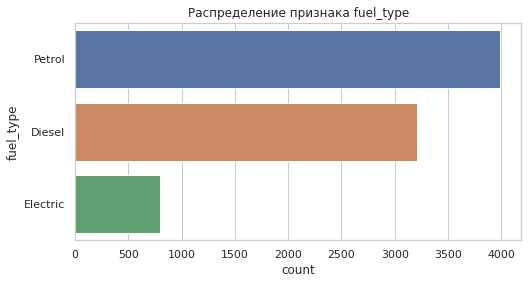

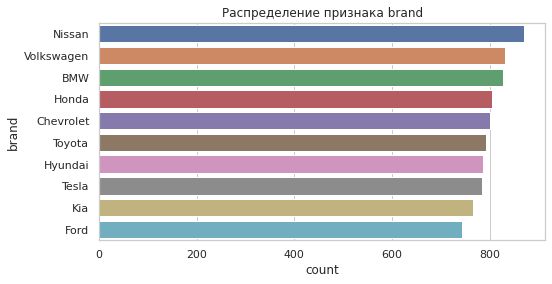

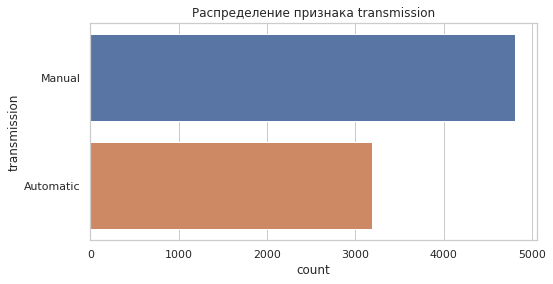

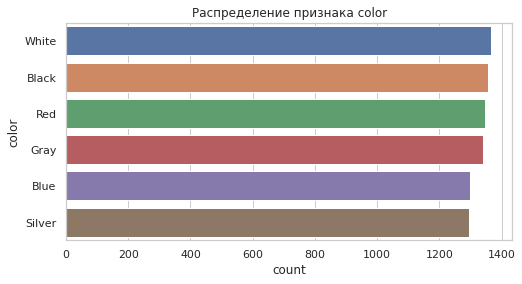

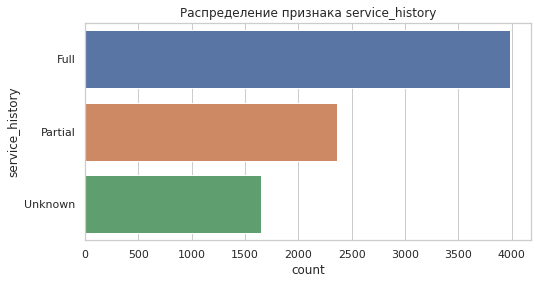

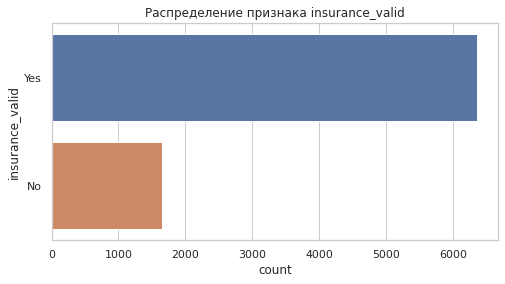

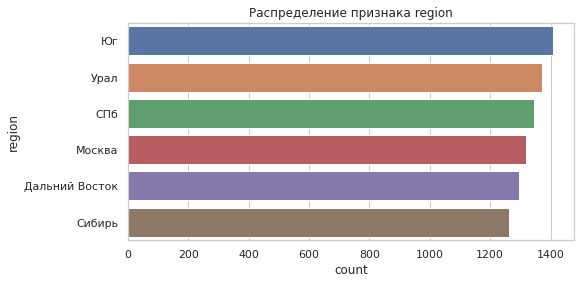

In [11]:
for col in cat_cols:

    plt.figure(figsize=(8,4))

    sns.countplot(
        data=train,
        y=col,
        order=train[col].value_counts().index
    )

    plt.title(f'Распределение признака {col}')

    plt.show()

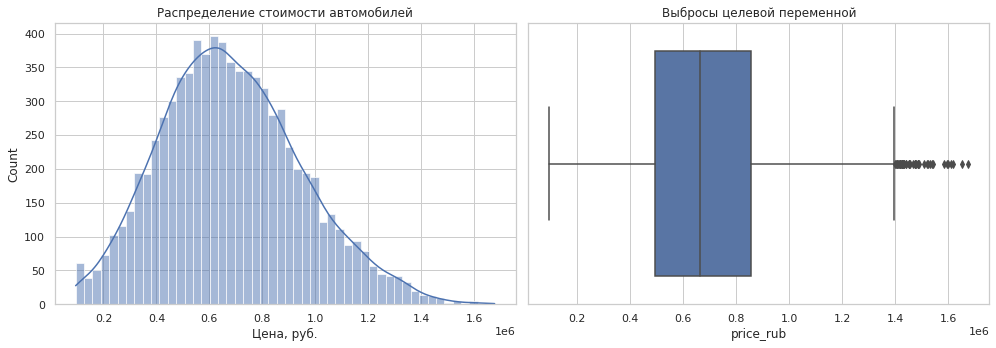

In [12]:
# Рассмотрим распределение стоимости автомобилей.

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14,5)
)

sns.histplot(
    train['price_rub'],
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Распределение стоимости автомобилей')
axes[0].set_xlabel('Цена, руб.')

sns.boxplot(
    x=train['price_rub'],
    ax=axes[1]
)

axes[1].set_title('Выбросы целевой переменной')

plt.tight_layout()
plt.show()

In [13]:
# Смотрим числовые характеристики целевой переменной.

train['price_rub'].describe()

count       8,000.00
mean      683,647.87
std       264,923.50
min        95,000.00
25%       493,857.00
50%       663,866.00
75%       855,056.00
max     1,676,525.00
Name: price_rub, dtype: float64

Поскольку в данных присутствует достаточное количество категориальных признаков, построим матрицу корреляиции PhiK.

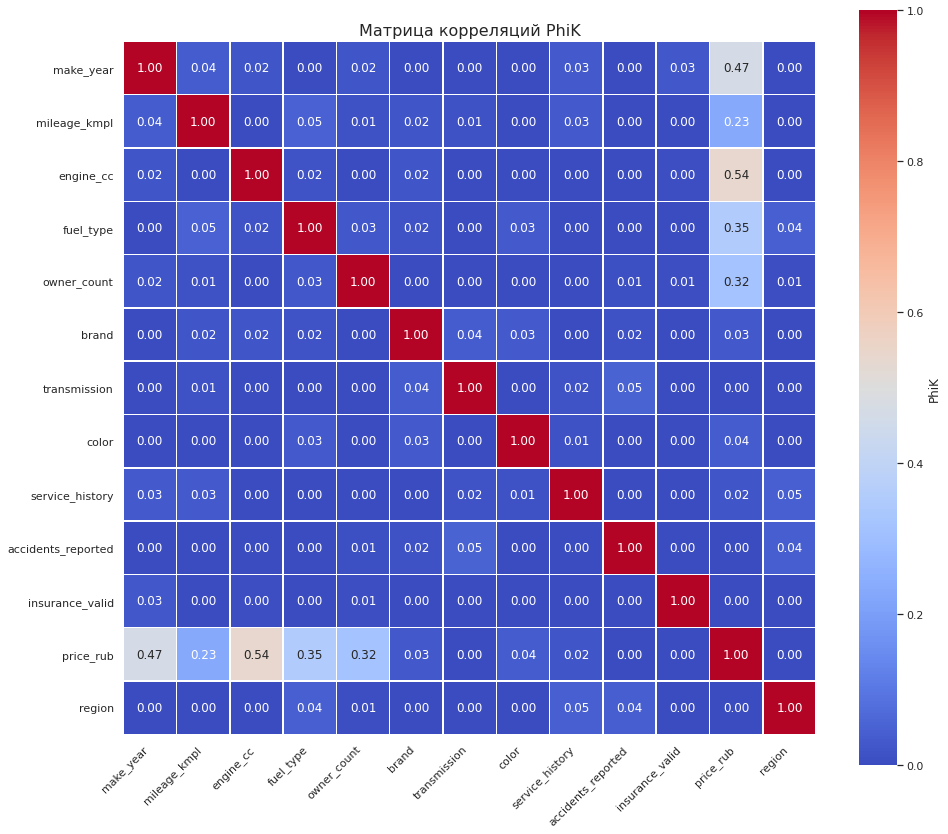

In [14]:
# числовые признаки
interval_cols = train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# расчет PhiK
phik_corr = train.phik_matrix(
    interval_cols=interval_cols
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    phik_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    square=True,
    cbar_kws={'label': 'PhiK'}
)

plt.title(
    'Матрица корреляций PhiK',
    fontsize=16
)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

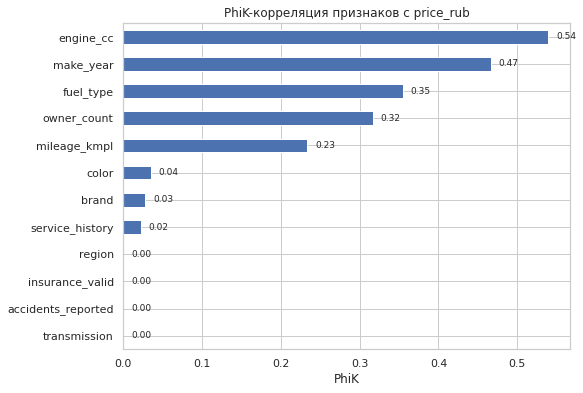

In [15]:
corr_target = phik_corr['price_rub'].drop('price_rub').sort_values()

ax = corr_target.plot(
    kind='barh',
    figsize=(8, 6)
)

for i, value in enumerate(corr_target.values):
    ax.text(
        value + 0.01,
        i,
        f'{value:.2f}',
        va='center',
        fontsize=9
    )

plt.title('PhiK-корреляция признаков с price_rub')
plt.xlabel('PhiK')
plt.show()

Наиболее сильная PhiK-связь с целевой переменной наблюдается у признаков:
* `engine_cc` — 0.54
* `make_year` — 0.47
* `fuel_type` — 0.35
* `owner_count` — 0.32
* `mileage_kmpl` — 0.23

По матрице PhiK наиболее выраженные связи с целевой переменной наблюдаются у следующих признаков.


# Вывод по обучающей выборке

Обучающая выборка содержит 8 000 наблюдений и включает числовые и категориальные признаки, характеризующие автомобиль, историю эксплуатации и регион продажи.

Средний год выпуска автомобиля — 2009 год; годы выпуска находятся в диапазоне от 1995 до 2023. Признак `mileage_kmpl` имеет медианное значение около 18. По названию он, вероятно, отражает топливную экономичность (км/л), а не общий пробег автомобиля, поэтому без дополнительного описания источника данных интерпретировать его как пробег нельзя. Объём двигателя у половины автомобилей находится в диапазоне от 1,2 до 3,0 л. Среднее и медианное количество предыдущих владельцев равны 3.

Большинство автомобилей не имеют зарегистрированных ДТП: медианное значение `accidents_reported` равно 0, среднее — 0,49.

Средняя стоимость автомобиля составляет 683 648 руб., медианная — 663 866 руб. Минимальная цена — 95 000 руб., максимальная — 1 676 525 руб. Среднее выше медианы, что согласуется с правосторонней асимметрией распределения цены.

Наиболее распространённый тип топлива — Petrol (49,9%); далее следуют Diesel (40,2%) и Electric (10,0%). Доли десяти марок находятся примерно в диапазоне 9,3–10,9%, распределение цветов также близко к равномерному. На автомобили с механической коробкой передач приходится 60,2% наблюдений, действующая страховка указана у 79,4% автомобилей. Полная сервисная история есть у 49,8% записей.

Распределения признаков не выглядят резко несбалансированными. При этом перед бизнес-интерпретацией важно уточнить смысл `mileage_kmpl` и происхождение остальных полей.


<AxesSubplot:xlabel='fuel_type', ylabel='price_rub'>

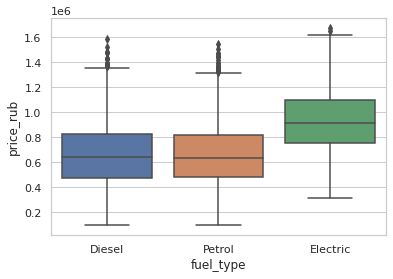

In [16]:
# Рассмотрим как тип двигателя связан с ценой

sns.boxplot(
    data=train,
    x='fuel_type',
    y='price_rub'
)

<AxesSubplot:xlabel='mileage_kmpl', ylabel='price_rub'>

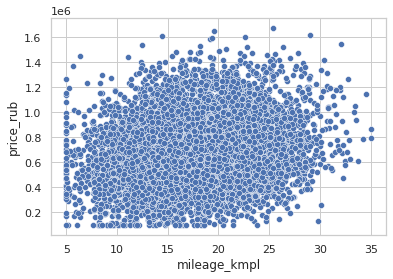

In [17]:
# Построим диаграмму рассеяния для mileage_kmpl и ценой

sns.scatterplot(
    data=train,
    x='mileage_kmpl',
    y='price_rub'
)

# Экспресс-обзор тестовой части датасета.

Сделаем экспресс-обзор тестовой части данных, чтобы исключить сюрпризы и некорретность данных.

In [18]:
# Смотрим общую статистику

test.info()
test.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   make_year           2000 non-null   int64  
 1   mileage_kmpl        2000 non-null   float64
 2   engine_cc           2000 non-null   int64  
 3   fuel_type           2000 non-null   object 
 4   owner_count         2000 non-null   int64  
 5   brand               2000 non-null   object 
 6   transmission        2000 non-null   object 
 7   color               2000 non-null   object 
 8   service_history     2000 non-null   object 
 9   accidents_reported  2000 non-null   int64  
 10  insurance_valid     2000 non-null   object 
 11  price_rub           2000 non-null   int64  
 12  region              2000 non-null   object 
dtypes: float64(1), int64(5), object(7)
memory usage: 203.2+ KB


,count,mean,std,min,25%,50%,75%,max
make_year,"2,000.00","2,009.15",8.32,"1,995.00","2,002.00","2,009.00","2,016.00","2,023.00"
mileage_kmpl,"2,000.00",18.02,5.07,5.00,14.57,18.01,21.38,34.38
engine_cc,"2,000.00","2,276.90","1,297.39",800.00,"1,200.00","1,800.00","3,000.00","5,000.00"
owner_count,"2,000.00",3.01,1.42,1.00,2.00,3.00,4.00,5.00
accidents_reported,"2,000.00",0.51,0.70,0.00,0.00,0.00,1.00,4.00
price_rub,"2,000.00","675,791.94","268,019.60","95,000.00","481,477.00","649,284.00","845,969.50","1,629,774.00"


In [19]:
cat_cols = test.select_dtypes(
    include=['object', 'category']
).columns

test[cat_cols].describe().T

,count,unique,top,freq
fuel_type,2000,3,Petrol,978
brand,2000,10,Tesla,222
transmission,2000,2,Manual,1173
color,2000,6,Gray,365
service_history,2000,3,Full,1002
insurance_valid,2000,2,Yes,1578
region,2000,6,Сибирь,357


In [20]:
# Проверим наличие пропусков.

test.isna().sum().sort_values(ascending=False)

make_year             0
mileage_kmpl          0
engine_cc             0
fuel_type             0
owner_count           0
brand                 0
transmission          0
color                 0
service_history       0
accidents_reported    0
insurance_valid       0
price_rub             0
region                0
dtype: int64

In [21]:
# Смотрим train

train.describe().T[['mean','std']]

,mean,std
make_year,"2,009.22",8.39
mileage_kmpl,17.95,5.02
engine_cc,"2,289.69","1,289.81"
owner_count,3.00,1.42
accidents_reported,0.49,0.69
price_rub,"683,647.87","264,923.50"


In [22]:
# Смотрим test
test.describe().T[['mean','std']]

,mean,std
make_year,"2,009.15",8.32
mileage_kmpl,18.02,5.07
engine_cc,"2,276.90","1,297.39"
owner_count,3.01,1.42
accidents_reported,0.51,0.70
price_rub,"675,791.94","268,019.60"


Тестовая выборка соответствует заявленным характеристикам и не содержит аномалий.

# 2. Предобработка данных

Формируем общие обучающую и валидационную выборки и подготавливаем признаки с учётом особенностей CatBoost, LightGBM и XGBoost. Тестовую выборку оставляем для финальной оценки.

In [23]:
# Разделим признаки на категории

TARGET = 'price_rub'

cat_cols = [
    'brand',
    'fuel_type',
    'transmission',
    'color',
    'service_history',
    'insurance_valid',
    'region'
]

num_cols = [
    col
    for col in train.columns
    if col not in cat_cols + [TARGET]
]

In [24]:
# Отделяем признаки

X = train.drop(columns=TARGET)

y = train[TARGET]

X_test_final = test.drop(columns=TARGET)

y_test_final = test[TARGET]

In [25]:
# Разделим обучающую выборку на Train и Validation

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

**XGBoost**

Для XGBoost необходимо закодировать категориальные признаки, будем использовать методод One-Hot Encoding с использованием OneHotEncoder(handle_unknown='ignore'), что обеспечивает одинаковую структуру признаков на обучающей, валидационной и тестовой выборках и позволяет корректно обрабатывать ранее не встречавшиеся категории.

In [26]:
X_train_xgb = X_train.copy()
X_valid_xgb = X_valid.copy()

X_test_xgb = X_test_final.copy()

for col in cat_cols:
    X_train_xgb[col] = X_train_xgb[col].astype('category')
    X_valid_xgb[col] = X_valid_xgb[col].astype('category')
    X_test_xgb[col] = X_test_xgb[col].astype('category')

**CatBoost**

Поскольку CatBoost умеет работать с категориальными признаками без дополнительной подготовки, в данном случае ничего делать не нужно.

In [27]:
X_train_cb = X_train.copy()
X_valid_cb = X_valid.copy()

X_test_cb = X_test_final.copy()

cat_features = cat_cols

**LightGBM**

Для LightGBM будем использовать нативную поддержку категорий.

In [28]:
X_train_lgb = X_train.copy()
X_valid_lgb = X_valid.copy()

X_test_lgb = X_test_final.copy()

In [29]:
for col in cat_cols:

    X_train_lgb[col] = (
        X_train_lgb[col]
        .astype('category')
    )

    X_valid_lgb[col] = (
        X_valid_lgb[col]
        .astype('category')
    )

    X_test_lgb[col] = (
        X_test_lgb[col]
        .astype('category')
    )

# 3. Обучение и сравнение базовых моделей

Сравниваем CatBoost, LightGBM и XGBoost по метрикам качества, бизнес-метрикам, а также времени обучения и предсказания. Дополнительно рассматриваем квантильную регрессию как способ изменить компромисс между риском переплаты и недооценки.

**3.1 Базовые модели**

Поскольку далее нам понадобится сравнивать не только качество, но и скорость, сразу реализуем замер времени обучения и предсказания.

Сначала сразу создадим функцию для бизнес-метрик, чтобы можно было получить таблицу результатов за один проход обучения.

In [30]:
def business_metrics(y_true, preds):

    error_ratio = (preds - y_true) / y_true

    overpricing_rate = (error_ratio > 0.20).mean()

    under_mask = (error_ratio < -0.20)

    underpricing_loss = (y_true[under_mask]- preds[under_mask]).sum()

    return overpricing_rate, underpricing_loss

Теперь универсальная функция оценки модели.

In [31]:
def evaluate_model(
        model,
        X_train,
        X_valid,
        y_train,
        y_valid,
        cat_features=None
):

    start_fit = time.time()

    if isinstance(model, CatBoostRegressor):

        model.fit(
            X_train,
            y_train,
            cat_features=cat_features,
            eval_set=(X_valid, y_valid),
            verbose=False
        )

    elif isinstance(model, LGBMRegressor):

        model.fit(
            X_train,
            y_train,
            eval_set=[(X_valid, y_valid)],
            eval_metric='mae',
        )

    elif isinstance(model, XGBRegressor):

        model.fit(
            X_train,
            y_train,
            eval_set=[(X_valid, y_valid)],
            verbose=False
        )

    else:

        model.fit(
            X_train,
            y_train
        )

    fit_time = time.time() - start_fit

    start_pred = time.time()

    preds = model.predict(X_valid)

    pred_time = (time.time() - start_pred)

    rmse = np.sqrt(mean_squared_error(y_valid, preds))

    mae = mean_absolute_error(y_valid, preds)

    r2 = r2_score(y_valid, preds)

    overpricing_rate, underpricing_loss = (business_metrics(y_valid, preds))

    return {

        'preds': preds,
        'rmse': rmse,
        'mae': mae,
        'r2': r2,
        'overpricing_rate': overpricing_rate,
        'underpricing_loss': underpricing_loss,
        'fit_time': fit_time,
        'pred_time': pred_time

    }

**XGBoost**

In [32]:
# Создаем XGBoost

xgb_model = XGBRegressor(
    objective='reg:absoluteerror',
    enable_categorical=True,
    tree_method='hist',
    eval_metric='mae',
    n_jobs=1,
    random_state=RANDOM_STATE
)

In [33]:
# Обучаем XGBoost

xgb_base_results = evaluate_model(
    xgb_model,
    X_train_xgb,
    X_valid_xgb,
    y_train,
    y_valid
)

**CatBoost**

In [34]:
# Создаем CatBoost

cb_model = CatBoostRegressor(
    random_seed=RANDOM_STATE,
    loss_function='MAE',
    eval_metric='MAE',
    thread_count=1,
    verbose=False
)

In [35]:
# Обучаем CatBoost

catboost_base_results = evaluate_model(
    cb_model,
    X_train_cb,
    X_valid_cb,
    y_train,
    y_valid,
    cat_features=cat_cols
)

**LightGBM**

In [36]:
# Создаем LightGBM

lgb_model = LGBMRegressor(
    random_state=RANDOM_STATE,
    objective='mae',
    n_jobs=1
)

In [37]:
# Обучаем LightGBM

lgb_base_results = evaluate_model(
    lgb_model,
    X_train_lgb,
    X_valid_lgb,
    y_train,
    y_valid
)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000485 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 347
[LightGBM] [Info] Number of data points in the train set: 6400, number of used features: 12
[LightGBM] [Info] Start training from score 662700.500000


In [38]:
dummy = DummyRegressor(
    strategy='median'
)

In [39]:
dummy_results = evaluate_model(
    dummy,
    X_train_xgb,   # можно использовать любую матрицу признаков
    X_valid_xgb,
    y_train,
    y_valid
)

In [40]:
# Собираем итоговую таблицу

results = pd.DataFrame({

    'Model': [
        'DummyRegressor',
        'XGBoost',
        'CatBoost',
        'LightGBM'
    ],

    'RMSE': [
        dummy_results['rmse'],
        xgb_base_results['rmse'],
        catboost_base_results['rmse'],
        lgb_base_results['rmse']
    ],

    'MAE': [
        dummy_results['mae'],
        xgb_base_results['mae'],
        catboost_base_results['mae'],
        lgb_base_results['mae']
    ],

    'R²': [
        dummy_results['r2'],
        xgb_base_results['r2'],
        catboost_base_results['r2'],
        lgb_base_results['r2']
    ],

    'Overpricing Rate': [
        dummy_results['overpricing_rate'],
        xgb_base_results['overpricing_rate'],
        catboost_base_results['overpricing_rate'],
        lgb_base_results['overpricing_rate']
    ],

    'Underpricing Loss': [
        dummy_results['underpricing_loss'],
        xgb_base_results['underpricing_loss'],
        catboost_base_results['underpricing_loss'],
        lgb_base_results['underpricing_loss']
    ],

    'Train Time (sec)': [
        dummy_results['fit_time'],
        xgb_base_results['fit_time'],
        catboost_base_results['fit_time'],
        lgb_base_results['fit_time']
    ],

    'Predict Time (sec)': [
        dummy_results['pred_time'],
        xgb_base_results['pred_time'],
        catboost_base_results['pred_time'],
        lgb_base_results['pred_time']
    ]

})

# Сортируем по MAE

results = results.sort_values(
    by='MAE',
    ignore_index=True
)

# Форматируем вывод

results.style.format({

    'RMSE': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'MAE': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'R²': '{:.4f}',
    'Overpricing Rate': '{:.2%}',
    'Underpricing Loss': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'Train Time (sec)': '{:.3f}',
    'Predict Time (sec)': '{:.4f}'

})

,Model,RMSE,MAE,R²,Overpricing Rate,Underpricing Loss,Train Time (sec),Predict Time (sec)
0,CatBoost,99 022,79 343,0.8552,13.38%,16 566 048,10.517,0.0058
1,LightGBM,102 804,81 979,0.8439,13.94%,19 556 105,0.146,0.0169
2,XGBoost,107 963,85 487,0.8279,14.44%,23 654 384,0.312,0.0129
3,DummyRegressor,261 177,206 847,-0.0072,31.81%,153 432 589,0.001,0.0001


**Вывод по базовым моделям**

Среди трёх базовых моделей градиентного бустинга лучшие результаты по выбранным метрикам показал CatBoost. Его RMSE составил 99 022 руб., MAE — 79 343 руб., R² — 0.8552. Для сравнения, LightGBM показал RMSE 102 804 руб., MAE 81 979 руб. и R² 0.8439; XGBoost — RMSE 107 963 руб., MAE 85 487 руб. и R² 0.8279.

CatBoost также показал наименьшие значения двух используемых бизнес-метрик среди этих моделей: Overpricing Rate — 13.38%, Underpricing Loss — 16 566 048 руб. У LightGBM эти показатели составили 13.94% и 19 556 105 руб., у XGBoost — 14.44% и 23 654 384 руб.

В сравнении моделей CatBoost обучался около 10,5 с, LightGBM — 0,146 с, XGBoost — 0,312 с. Следовательно, CatBoost оказался точнее по выбранным метрикам, но обучался дольше. Это компромисс, который следует учитывать вместе с требованиями к частоте переобучения и задержке в рабочем процессе.

На основании этих результатов CatBoost выбран для дальнейших экспериментов. Это вывод в рамках данного разбиения и набора метрик, а не доказательство того, что библиотека будет лучшей для любых данных.


**Исследуем Quantile Loss**

Реализуем осторожную модель CatBoost через квантильный лосс.

In [41]:
# Создадим таблицу сравнений базовой CatBoost и Quantile Loss

comparison = [
    {
        'Model': 'CatBoost (MAE)',
        'RMSE': catboost_base_results['rmse'],
        'MAE': catboost_base_results['mae'],
        'R²': catboost_base_results['r2'],
        'Overpricing Rate': catboost_base_results['overpricing_rate'],
        'Underpricing Loss': catboost_base_results['underpricing_loss'],
        'Train Time (sec)': catboost_base_results['fit_time'],
        'Predict Time (sec)': catboost_base_results['pred_time']
    }
]

In [42]:
alphas = [0.50, 0.45, 0.40, 0.35] # задаём параметры функции потерь


quantile_results = []

for alpha in alphas:

    model = CatBoostRegressor(
        loss_function=f'Quantile:alpha={alpha}',
        random_seed=RANDOM_STATE,
        verbose=False
    )

    result = evaluate_model(
        model,
        X_train_cb,
        X_valid_cb,
        y_train,
        y_valid,
        cat_features=cat_cols
    )

    comparison.append({
    'Model': f'Quantile (α={alpha:.2f})',
    'RMSE': result['rmse'],
    'MAE': result['mae'],
    'R²': result['r2'],
    'Overpricing Rate': result['overpricing_rate'],
    'Underpricing Loss': result['underpricing_loss'],
    'Train Time (sec)': result['fit_time'],
    'Predict Time (sec)': result['pred_time']
    })

In [43]:
comparison = pd.DataFrame(comparison)

comparison.style.format({

    'RMSE': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'MAE': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'R²':'{:.4f}',
    'Overpricing Rate':'{:.2%}',
    'Underpricing Loss': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'Train Time (sec)':'{:.3f}',
    'Predict Time (sec)':'{:.4f}'

})

,Model,RMSE,MAE,R²,Overpricing Rate,Underpricing Loss,Train Time (sec),Predict Time (sec)
0,CatBoost (MAE),99 022,79 343,0.8552,13.38%,16 566 048,10.517,0.0058
1,Quantile (α=0.50),99 022,79 343,0.8552,13.38%,16 566 048,10.878,0.0059
2,Quantile (α=0.45),100 419,80 440,0.8511,12.31%,22 836 307,9.964,0.0073
3,Quantile (α=0.40),102 770,82 541,0.8441,10.56%,30 061 602,11.017,0.0061
4,Quantile (α=0.35),106 286,85 530,0.8332,9.00%,36 784 045,10.069,0.0057


**Вывод по Quantile Loss**

В эксперименте с Quantile Loss уменьшение параметра квантиля α снижает Overpricing Rate, но одновременно ухудшает стандартные метрики качества и увеличивает Underpricing Loss.

Модель с α = 0.50 совпадает с базовой моделью CatBoost, обученной с MAE, по полученным показателям: RMSE — 99 022 руб., MAE — 79 343 руб., R² — 0.8552, Overpricing Rate — 13.38%, Underpricing Loss — 16 566 048 руб.

При α = 0.45 Overpricing Rate снижается до 12.31%, а Underpricing Loss увеличивается до 22 836 307 руб. При α = 0.40 показатели составляют 10.56% и 30 061 602 руб.; при α = 0.35 — 9.00% и 36 784 045 руб. Таким образом, самое низкое значение Overpricing Rate в этом эксперименте достигается ценой заметно большего Underpricing Loss.

Среди протестированных вариантов α = 0.45 выглядит компромиссом, если снижение риска завышения цены для бизнеса важнее роста риска недооценки. Выбирать этот вариант без согласования стоимости двух типов ошибок с бизнесом не следует.


# 4. Подбор гиперпараметров

Используем Optuna для настройки CatBoost, LightGBM и XGBoost и сравниваем лучшие конфигурации на валидационной выборке.

In [44]:
# Задаём количество испытаний

N_TRIALS = 50

**Подбор гиперпараметров XGBoost**

In [45]:
def objective_xgb(trial):

    params = {
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'n_estimators': trial.suggest_int('n_estimators', 500, 2000),
        'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'objective': 'reg:absoluteerror',
        'eval_metric': 'mae',
        'enable_categorical': True,
        'tree_method': 'hist',
        'early_stopping_rounds': 50,
        'random_state': RANDOM_STATE,
        'n_jobs': -1
    }

    model = XGBRegressor(**params)

    model.fit(
        X_train_xgb,
        y_train,
        eval_set=[(X_valid_xgb, y_valid)],
        verbose=False
    )

    preds = model.predict(X_valid_xgb)

    return mean_absolute_error(y_valid, preds)

In [46]:
# Запуск для XGBoost

study_xgb = optuna.create_study(direction='minimize')

study_xgb.optimize(objective_xgb, n_trials=N_TRIALS)

[I 2026-08-01 00:32:46,346] A new study created in memory with name: no-name-6f21e1e1-bac1-4de2-9637-af6242b7d6d1
[I 2026-08-01 00:32:48,548] Trial 0 finished with value: 80399.4765625 and parameters: {'learning_rate': 0.013042093342793545, 'max_depth': 3, 'n_estimators': 1833, 'gamma': 0.0001532783467497296, 'reg_alpha': 0.47327329417528635, 'reg_lambda': 5.154994437288626e-05}. Best is trial 0 with value: 80399.4765625.
[I 2026-08-01 00:32:49,778] Trial 1 finished with value: 82209.8125 and parameters: {'learning_rate': 0.02764985871478309, 'max_depth': 6, 'n_estimators': 1184, 'gamma': 5.36361967001203e-05, 'reg_alpha': 0.001671772781566434, 'reg_lambda': 3.433877875625815e-06}. Best is trial 0 with value: 80399.4765625.
[I 2026-08-01 00:32:50,385] Trial 2 finished with value: 81032.2421875 and parameters: {'learning_rate': 0.04895709153633535, 'max_depth': 4, 'n_estimators': 1882, 'gamma': 2.0270334237968899e-07, 'reg_alpha': 0.004401779846960408, 'reg_lambda': 2.143030126502247}. 

In [47]:
# Лучшие параметры XGBoost

print(f'Лучшие параметры XGBoost:')
study_xgb.best_params

Лучшие параметры XGBoost:


{'learning_rate': 0.022056097561765794,
 'max_depth': 3,
 'n_estimators': 1710,
 'gamma': 2.6085646573313616e-05,
 'reg_alpha': 3.270701553561525e-05,
 'reg_lambda': 4.789319613722624e-07}

In [48]:
# Лучшее значение MAE для XGBoost

print(f'Лучшее значение MAE для XGBoost: {study_xgb.best_value}')

Лучшее значение MAE для XGBoost: 80287.1796875


**Подбор гиперпараметров CatBoost**

In [49]:
def objective_catboost(trial):

    params = {
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 3, 10),
        'iterations': trial.suggest_int('iterations', 500, 2000),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 10),
        'loss_function': 'MAE',
        'eval_metric': 'MAE',
        'early_stopping_rounds': 50,
        'use_best_model': True,
        'random_seed': RANDOM_STATE,
        'verbose': False
    }

    model = CatBoostRegressor(**params)

    model.fit(
        X_train_cb,
        y_train,
        cat_features=cat_cols,
        eval_set=(X_valid_cb, y_valid)
    )

    preds = model.predict(X_valid_cb)

    return mean_absolute_error(y_valid, preds)

In [50]:
# Запуск для CatBoost

study_catboost = optuna.create_study(direction='minimize')

study_catboost.optimize(objective_catboost, n_trials=N_TRIALS)

[I 2026-08-01 00:34:05,083] A new study created in memory with name: no-name-429666ad-b370-4e56-9062-76698370e2eb
[I 2026-08-01 00:34:12,841] Trial 0 finished with value: 80215.2725116312 and parameters: {'learning_rate': 0.049411682566728836, 'depth': 10, 'iterations': 985, 'l2_leaf_reg': 5.219761277805306}. Best is trial 0 with value: 80215.2725116312.
[I 2026-08-01 00:34:23,664] Trial 1 finished with value: 79991.90208048382 and parameters: {'learning_rate': 0.02725826558368872, 'depth': 9, 'iterations': 1113, 'l2_leaf_reg': 1.681381274177487}. Best is trial 1 with value: 79991.90208048382.
[I 2026-08-01 00:34:29,782] Trial 2 finished with value: 80074.76878908457 and parameters: {'learning_rate': 0.010798920327079095, 'depth': 6, 'iterations': 544, 'l2_leaf_reg': 2.111975109887494}. Best is trial 1 with value: 79991.90208048382.
[I 2026-08-01 00:34:57,173] Trial 3 finished with value: 80006.04123599955 and parameters: {'learning_rate': 0.011835008892158171, 'depth': 10, 'iterations

In [51]:
# Лучшие параметры CatBoost

print(f'Лучшие параметры CatBoost:')
study_catboost.best_params

Лучшие параметры CatBoost:


{'learning_rate': 0.06302085357291862,
 'depth': 4,
 'iterations': 1652,
 'l2_leaf_reg': 8.304709353940861}

In [52]:
# Лучшее значение MAE для CatBoost

print(f'Лучшее значение MAE для XGBoost: {study_catboost.best_value}')

Лучшее значение MAE для XGBoost: 79240.42018991648


**Подбор гиперпараметров LightGBM**

In [53]:
def objective_lgb(trial):

    params = {
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'n_estimators': trial.suggest_int('n_estimators', 500, 2000),
        'num_leaves': trial.suggest_int('num_leaves', 20, 256),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 1.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 1.0, log=True),
        'objective': 'mae',
        'verbosity': -1,
        'force_row_wise': True,
        'random_state': RANDOM_STATE,
        'n_jobs': -1
    }

    model = LGBMRegressor(**params)

    model.fit(
        X_train_lgb,
        y_train,
        eval_set=[(X_valid_lgb, y_valid)],
        eval_metric='mae',
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=50,
                verbose=False
            )
        ]
    )

    preds = model.predict(
        X_valid_lgb,
        num_iteration=model.best_iteration_
    )

    return mean_absolute_error(y_valid, preds)

In [54]:
# Запуск для LightGBM

study_lgb = optuna.create_study(direction='minimize')

study_lgb.optimize(objective_lgb, n_trials=N_TRIALS)

[I 2026-08-01 00:39:10,128] A new study created in memory with name: no-name-1b45d98a-2fbd-4ffa-b15e-92bd6040d7ea
[I 2026-08-01 00:39:10,904] Trial 0 finished with value: 81042.6654677283 and parameters: {'learning_rate': 0.010686538867256713, 'max_depth': 4, 'n_estimators': 826, 'num_leaves': 235, 'min_child_samples': 92, 'reg_alpha': 7.058159090040421e-08, 'reg_lambda': 1.7178170421017772e-06}. Best is trial 0 with value: 81042.6654677283.
[I 2026-08-01 00:39:11,610] Trial 1 finished with value: 81017.06477755934 and parameters: {'learning_rate': 0.021374714366137828, 'max_depth': 6, 'n_estimators': 1316, 'num_leaves': 20, 'min_child_samples': 40, 'reg_alpha': 0.00021188811074518367, 'reg_lambda': 0.7144683847747278}. Best is trial 1 with value: 81017.06477755934.
[I 2026-08-01 00:39:12,601] Trial 2 finished with value: 82991.02705209941 and parameters: {'learning_rate': 0.017703282812416073, 'max_depth': 7, 'n_estimators': 1327, 'num_leaves': 205, 'min_child_samples': 5, 'reg_alpha'

In [55]:
# Лучшие параметры LightGBM

print(f'Лучшие параметры LightGBM:')
study_lgb.best_params

Лучшие параметры LightGBM:


{'learning_rate': 0.07506256385921224,
 'max_depth': 3,
 'n_estimators': 1744,
 'num_leaves': 30,
 'min_child_samples': 13,
 'reg_alpha': 1.5953327411342321e-06,
 'reg_lambda': 0.0012202911386759664}

In [56]:
# Лучшее значение MAE для LightGBM

print(f'Лучшее значение MAE для LightGBM: {study_lgb.best_value}')

Лучшее значение MAE для LightGBM: 80123.84220895014


**Создание лучших моделей**

In [57]:
# Лучшая модель для XGBoost

best_xgb = XGBRegressor(
    **study_xgb.best_params,
    objective='reg:absoluteerror',
    eval_metric='mae',
    enable_categorical=True,
    tree_method='hist',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_tuned_results = evaluate_model(
    best_xgb,
    X_train_xgb,
    X_valid_xgb,
    y_train,
    y_valid
)

In [58]:
# Лучшая модель для CatBoost

best_catboost = CatBoostRegressor(
    **study_catboost.best_params,
    loss_function='MAE',
    random_seed=RANDOM_STATE,
    verbose=False
)

catboost_tuned_results = evaluate_model(
    best_catboost,
    X_train_cb,
    X_valid_cb,
    y_train,
    y_valid,
    cat_features=cat_cols
)

In [59]:
# Лучшая модель для LightGBM

best_lgb = LGBMRegressor(
    **study_lgb.best_params,
    objective='mae',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

lgb_tuned_results = evaluate_model(
    best_lgb,
    X_train_lgb,
    X_valid_lgb,
    y_train,
    y_valid
)

**Сравниваем лучшие модели**

In [60]:
results_optuna = pd.DataFrame({

    'Model': [
        'XGBoost',
        'CatBoost',
        'LightGBM'
    ],

    'RMSE': [
        xgb_tuned_results['rmse'],
        catboost_tuned_results['rmse'],
        lgb_tuned_results['rmse']
    ],

    'MAE': [
        xgb_tuned_results['mae'],
        catboost_tuned_results['mae'],
        lgb_tuned_results['mae']
    ],

    'R²': [
        xgb_tuned_results['r2'],
        catboost_tuned_results['r2'],
        lgb_tuned_results['r2']
    ],

    'Overpricing Rate': [
        xgb_tuned_results['overpricing_rate'],
        catboost_tuned_results['overpricing_rate'],
        lgb_tuned_results['overpricing_rate']
    ],

    'Underpricing Loss': [
        xgb_tuned_results['underpricing_loss'],
        catboost_tuned_results['underpricing_loss'],
        lgb_tuned_results['underpricing_loss']
    ],

    'Train Time (sec)': [
        xgb_tuned_results['fit_time'],
        catboost_tuned_results['fit_time'],
        lgb_tuned_results['fit_time']
    ],

    'Predict Time (sec)': [
        xgb_tuned_results['pred_time'],
        catboost_tuned_results['pred_time'],
        lgb_tuned_results['pred_time']
    ]

}).sort_values(
    by='MAE',
    ignore_index=True
)

results_optuna.style.format({

    'RMSE': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'MAE': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'R²':'{:.4f}',
    'Overpricing Rate':'{:.2%}',
    'Underpricing Loss': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'Train Time (sec)':'{:.3f}',
    'Predict Time (sec)':'{:.4f}'

})

,Model,RMSE,MAE,R²,Overpricing Rate,Underpricing Loss,Train Time (sec),Predict Time (sec)
0,CatBoost,98 954,79 228,0.8554,13.63%,17 464 747,15.649,0.0054
1,XGBoost,100 847,80 374,0.8498,13.25%,19 334 325,3.241,0.0423
2,LightGBM,101 477,80 820,0.8480,13.56%,20 548 204,1.080,0.1730


**Вывод по подбору гиперпараметров с помощью Optuna**

После подбора гиперпараметров CatBoost сохранил лидерство по стандартным метрикам среди трёх моделей. Его RMSE составил 98 954 руб., MAE — 79 228 руб., R² — 0.8554. У XGBoost получены RMSE 100 847 руб., MAE 80 374 руб. и R² 0.8498; у LightGBM — RMSE 101 477 руб., MAE 80 820 руб. и R² 0.8480.

По бизнес-метрикам CatBoost также показал наименьший Underpricing Loss — 17 464 747 руб. Overpricing Rate составил 13.63%. У XGBoost соответствующие значения равны 19 334 325 руб. и 13.25%, у LightGBM — 20 548 204 руб. и 13.56%. Поэтому CatBoost не минимизирует Overpricing Rate: по этой метрике в этом сравнении лучший результат у XGBoost.

Время обучения составило 15,649 с для CatBoost, 3,241 с для XGBoost и 1,080 с для LightGBM. Время предсказания — 0,0054 с, 0,0423 с и 0,1730 с соответственно. Это значения конкретного сохранённого запуска, зависящие от оборудования и окружения.

В целом CatBoost выбран как основной кандидат благодаря лучшим RMSE, MAE и R² и наименьшему Underpricing Loss. При этом бизнесу следует отдельно оценить компромисс: у XGBoost ниже Overpricing Rate.


# 5. Интерпретация моделей и бизнес-анализ

Используем SHAP для анализа значимости признаков и изучаем ошибки моделей в разрезе марок автомобилей и регионов.

In [61]:
# Обучение лучших моделей

best_xgb = XGBRegressor(
    **study_xgb.best_params,
    objective='reg:absoluteerror',
    eval_metric='mae',
    enable_categorical=True,
    tree_method='hist',
    early_stopping_rounds=50,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_tuned_results = evaluate_model(
    best_xgb,
    X_train_xgb,
    X_valid_xgb,
    y_train,
    y_valid
)



best_lgb = LGBMRegressor(
    **study_lgb.best_params,
    objective='mae',
    random_state=RANDOM_STATE,
    verbosity=-1,
    force_row_wise=True,
    n_jobs=-1
)

lgb_tuned_results = evaluate_model(
    best_lgb,
    X_train_lgb,
    X_valid_lgb,
    y_train,
    y_valid
)


best_catboost = CatBoostRegressor(
    **study_catboost.best_params,
    loss_function='MAE',
    eval_metric='MAE',
    early_stopping_rounds=50,
    use_best_model=True,
    random_seed=RANDOM_STATE,
    verbose=False
)

catboost_tuned_results = evaluate_model(
    best_catboost,
    X_train_cb,
    X_valid_cb,
    y_train,
    y_valid,
    cat_features=cat_cols
)

In [62]:
# Собираем модели

models = {
    'CatBoost': {
        'model': best_catboost,
        'X_valid': X_valid_cb
    },

    'LightGBM': {
        'model': best_lgb,
        'X_valid': X_valid_lgb
    },

    'XGBoost': {
        'model': best_xgb,
        'X_valid': X_valid_xgb
    }
}

In [63]:
# Расчитываем SHAP

for name, data in models.items():

    print(f'Calculating SHAP for {name}...')

    explainer = shap.TreeExplainer(
        data['model']
    )

    shap_values = explainer.shap_values(
        data['X_valid']
    )

    feature_importance = (
        pd.DataFrame({
            'Feature': data['X_valid'].columns,
            'Mean |SHAP|': np.abs(
                shap_values
            ).mean(axis=0)
        })
        .sort_values(
            by='Mean |SHAP|',
            ascending=False
        )
        .reset_index(drop=True)
    )

    data['explainer'] = explainer
    data['shap_values'] = shap_values
    data['importance'] = feature_importance

Calculating SHAP for CatBoost...
Calculating SHAP for LightGBM...
Calculating SHAP for XGBoost...


In [64]:
# Напишем функцию для построения графиков

def plot_summary(model_name):

    data = models[model_name]

    plt.figure(figsize=(10, 6))

    shap.summary_plot(
        data['shap_values'],
        data['X_valid'],
        show=False
    )

    plt.title(f'{model_name} SHAP Summary Plot')

    plt.tight_layout()

    plt.show()

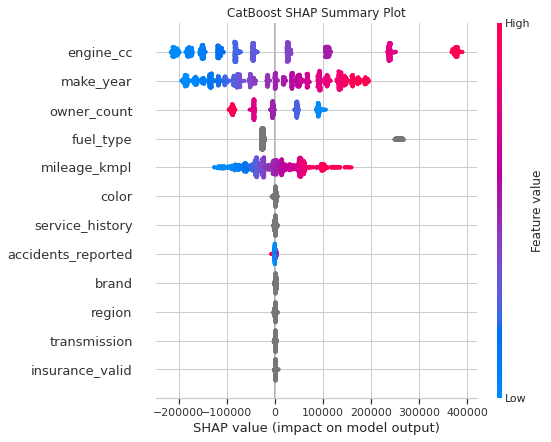

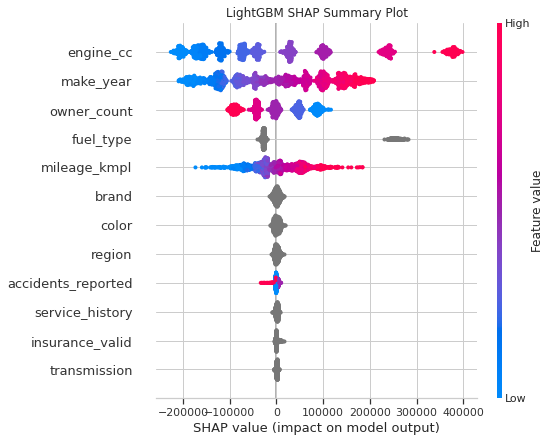

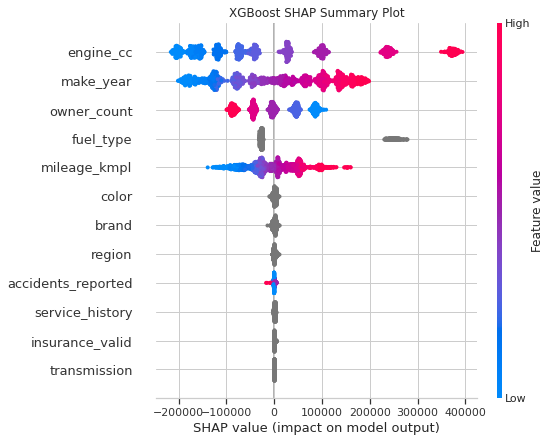

In [65]:
# Строим графики

for model_name in models:

    plot_summary(model_name)

In [66]:
# Top-5 наиболее важных признаков для каждой модели

for model_name in models:

    print('=' * 70)
    print(model_name)
    print('=' * 70)

    display(
        models[model_name]['importance'].head()
    )

CatBoost


,Feature,Mean |SHAP|
0,engine_cc,"147,447.93"
1,make_year,"102,584.66"
2,owner_count,"53,524.38"
3,fuel_type,"49,569.83"
4,mileage_kmpl,"46,283.03"


LightGBM


,Feature,Mean |SHAP|
0,engine_cc,"145,331.30"
1,make_year,"103,172.12"
2,owner_count,"53,207.71"
3,fuel_type,"50,968.64"
4,mileage_kmpl,"44,683.83"


XGBoost


,Feature,Mean |SHAP|
0,engine_cc,"144,269.67"
1,make_year,"102,212.51"
2,owner_count,"52,036.77"
3,fuel_type,"50,078.90"
4,mileage_kmpl,"44,692.67"


In [67]:
# Сводная таблица Top-5

top5 = pd.DataFrame({
    model_name: (
        data['importance']
        ['Feature']
        .head(5)
        .values
    )
    for model_name, data in models.items()
})

top5.index = np.arange(1, 6)

top5.index.name = 'Rank'

top5

,CatBoost,LightGBM,XGBoost
Rank,,,
1,engine_cc,engine_cc,engine_cc
2,make_year,make_year,make_year
3,owner_count,owner_count,owner_count
4,fuel_type,fuel_type,fuel_type
5,mileage_kmpl,mileage_kmpl,mileage_kmpl


SHAP-анализ показывает одинаковую пятёрку наиболее важных признаков во всех трёх оптимизированных моделях: `engine_cc`, `make_year`, `owner_count`, `fuel_type` и `mileage_kmpl`. Это указывает на сходство выявленных моделью факторов в рамках данного набора данных.

У XGBoost категориальные признаки представлены после One-Hot Encoding, однако в таблице агрегированной важности верхняя пятёрка также содержит `fuel_type`. Не следует делать вывод, что `fuel_type_Electric` занимает первое место: такого результата таблица не показывает.


In [78]:
# Анализ признаков color и insurance_valid для CatBoost и LightGBM

for model_name in ['CatBoost', 'LightGBM', 'XGBoost']:

    print(f'\n{model_name}')

    display(
        models[model_name]['importance'][
            models[model_name]['importance']['Feature'].isin(
                ['color', 'insurance_valid']
            )
        ]
    )


CatBoost


,Feature,Mean |SHAP|
5,color,"1,296.00"
11,insurance_valid,428.59



LightGBM


,Feature,Mean |SHAP|
6,color,"4,129.60"
10,insurance_valid,"1,426.13"



XGBoost


,Feature,Mean |SHAP|
5,color,"2,331.99"
10,insurance_valid,555.67


Анализ SHAP показывает, что признаки `color` и `insurance_valid` оказывают значительно меньшее влияние на прогноз стоимости автомобиля по сравнению с техническими характеристиками, такими как объём двигателя, год выпуска, количество владельцев и расход топлива.

SHAP-анализ показал практически полное совпадение результатов для CatBoost, LightGBM и XGBoost. Во всех трех моделях наиболее значимыми признаками оказались `engine_cc`, `make_year`, `owner_count`, `fuel_type` и `mileage_kmpl`. Совпадение порядка признаков и близкие значения SHAP подтверждают устойчивость полученных результатов и свидетельствуют о том, что разные реализации градиентного бустинга выявляют одни и те же закономерности в данных.

Анализ SHAP Summary Plot позволяет определить и направление влияния признаков на прогноз стоимости автомобиля.

* `engine_cc` — наиболее важный признак. Большие значения объема двигателя (красные точки) расположены преимущественно в области положительных SHAP-значений, тогда как небольшие объемы двигателя (синие точки) — в области отрицательных. Следовательно, увеличение объема двигателя приводит к увеличению прогнозируемой стоимости автомобиля.
* `make_year` — более новые автомобили оказывают положительное влияние на цену, тогда как старые автомобили уменьшают прогнозируемую стоимость. Это полностью соответствует ожиданиям.
* `owner_count` — наблюдается обратная зависимость. Автомобили с большим количеством предыдущих владельцев (красные точки) чаще имеют отрицательные SHAP-значения, а автомобили с небольшим числом владельцев — положительные. Таким образом, увеличение количества владельцев снижает прогнозируемую стоимость автомобиля.
* `fuel_type` оказывает выраженное влияние на прогноз. На графиках хорошо видно наличие отдельной группы объектов с высокими положительными SHAP-значениями. Это говорит о том, что один из типов топлива существенно повышает стоимость автомобиля. С учетом результатов исследовательского анализа данных наиболее вероятно, что речь идет об электромобилях, которые в рассматриваемом наборе данных имеют более высокую стоимость.
* `mileage_kmpl` демонстрирует преимущественно положительную зависимость: более высокие значения признака чаще соответствуют положительным SHAP-значениям, а низкие — отрицательным. Следовательно, автомобили с более высокой топливной экономичностью в среднем получают более высокую прогнозируемую стоимость. При этом влияние признака менее выражено, чем у четырех лидеров, и имеет нелинейный характер, что указывает на его взаимодействие с другими характеристиками автомобиля.

Остальные признаки (`color`, `brand`, `region`, `accidents_reported`, `service_history`, `insurance_valid`, `transmission`) имеют существенно меньшие значения SHAP. Их вклад в прогноз стоимости значительно ниже, поэтому модели используют их преимущественно как дополнительные уточняющие факторы, тогда как основное решение принимается на основе технических характеристик автомобиля.

**Анализ ошибок**

Проанализируем ошибки в разрезе категорий (марки автомобилей и макро-регионов).

Получаем предсказания CatBoost, т.к. ранее мы опредлили что это лучшая модель:

In [70]:
y_pred = best_catboost.predict(X_valid_cb)

Создаем таблицу с ошибками.

In [71]:
analysis = X_valid.copy()

analysis['actual_price'] = y_valid.values
analysis['predicted_price'] = y_pred

analysis['error_ratio'] = (
    analysis['predicted_price'] - analysis['actual_price']
) / analysis['actual_price']

analysis['abs_error'] = (
    analysis['predicted_price'] - analysis['actual_price']
).abs()

analysis['overpricing'] = analysis['error_ratio'] > 0.20

analysis['underpricing'] = analysis['error_ratio'] < -0.20

analysis['underpricing_loss'] = np.where(
    analysis['underpricing'],
    analysis['actual_price'] - analysis['predicted_price'],
    0
)

Смотрим ошибки по маркам.

In [72]:
brand_analysis = (
    analysis
    .groupby('brand')
    .agg(
        Count=('brand', 'size'),
        MAE=('abs_error', 'mean'),
        Overpricing_Rate=('overpricing', 'mean'),
        Underpricing_Loss=('underpricing_loss', 'sum')
    )
    .sort_values(
        by='Overpricing_Rate',
        ascending=False
    )
)

brand_analysis

,Count,MAE,Overpricing_Rate,Underpricing_Loss
brand,,,,
Toyota,152,"86,498.13",0.18,"2,061,397.76"
Volkswagen,173,"75,938.17",0.16,"1,898,752.29"
Ford,147,"77,659.92",0.15,"1,223,476.66"
Tesla,163,"86,338.99",0.15,"1,784,422.63"
Honda,132,"70,803.67",0.13,"646,016.28"
Hyundai,166,"77,678.93",0.13,"1,383,412.51"
Chevrolet,159,"71,382.47",0.13,"1,616,126.85"
Nissan,170,"74,697.94",0.12,"1,758,255.34"
BMW,171,"86,178.43",0.12,"3,104,279.46"


Смотрим ошибки по регионам.

In [73]:
region_analysis = (
    analysis
    .groupby('region')
    .agg(
        Count=('region', 'size'),
        MAE=('abs_error', 'mean'),
        Overpricing_Rate=('overpricing', 'mean'),
        Underpricing_Loss=('underpricing_loss', 'sum')
    )
    .sort_values(
        by='Overpricing_Rate',
        ascending=False
    )
)

region_analysis

,Count,MAE,Overpricing_Rate,Underpricing_Loss
region,,,,
Сибирь,253,"81,388.74",0.16,"2,300,349.72"
Урал,276,"82,011.07",0.16,"1,973,282.57"
Юг,293,"76,986.08",0.15,"3,607,749.39"
Москва,249,"76,264.04",0.14,"2,454,917.60"
СПб,267,"77,827.84",0.13,"3,657,098.67"
Дальний Восток,262,"81,036.51",0.08,"3,369,329.97"


**Вывод по ошибкам по маркам и регионам**

По таблице наибольшая MAE по маркам наблюдается у Toyota (86 498 руб.), Tesla (86 339 руб.) и BMW (86 178 руб.). Наименьшая — у Honda (70 804 руб.), Chevrolet (71 382 руб.) и Nissan (74 698 руб.). Количество объектов по маркам находится в диапазоне 132–173 наблюдения, поэтому оценки по отдельным маркам всё же стоит трактовать с учётом ограниченного размера групп.

По регионам наибольшая MAE зафиксирована на Урале (82 011 руб.), в Сибири (81 389 руб.) и на Дальнем Востоке (81 037 руб.). Наименьшая — на Юге (76 986 руб.), в Москве (76 264 руб.) и Санкт-Петербурге (77 828 руб.). В группах от 249 до 293 наблюдений. Эти различия могут служить ориентиром для дальнейшей проверки, но сами по себе не доказывают систематическую причину ошибок.


С точки зрения бизнес-метрик важно отдельно рассматривать риск завышения цены и суммарные потери от недооценки.

По маркам наибольший Overpricing Rate в таблице у Toyota (18%), Volkswagen (16%), Ford (15%) и Tesla (15%). Наибольший Underpricing Loss наблюдается у BMW (3,10 млн руб.), Toyota (2,06 млн руб.) и Volkswagen (1,90 млн руб.). Это разные типы риска, поэтому не стоит объединять их в один рейтинг.

По регионам максимальный Overpricing Rate зафиксирован в Сибири и на Урале (по 16%), далее идёт Юг (15%). Наибольший Underpricing Loss — в Санкт-Петербурге (3,66 млн руб.), на Юге (3,61 млн руб.) и Дальнем Востоке (3,37 млн руб.).

Эти групповые результаты можно использовать для постановки гипотез и определения направлений дополнительной проверки. Для практического решения нужны оценка статистической неопределённости и согласованные с бизнесом пороги риска.


# 6. Финальная оценка на тестовой выборке

После выбора модели и настройки гиперпараметров оцениваем качество на отложенной тестовой выборке, не использовавшейся для выбора модели.

In [74]:
# Получаем предсказание для лучшей модели

y_test_final_pred = best_catboost.predict(X_test_cb)

In [75]:
# Рассчитываем метрики для теста

test_rmse = np.sqrt(mean_squared_error(y_test_final, y_test_final_pred))

test_mae = mean_absolute_error(y_test_final, y_test_final_pred)

test_r2 = r2_score(y_test_final, y_test_final_pred)

test_overpricing_rate, test_underpricing_loss = business_metrics(
    y_test_final,
    y_test_final_pred
)

In [76]:
# Создаём таблицу с результатами тестовой выборки

test_results_final = pd.DataFrame({
    'Model': ['CatBoost'],
    'RMSE': [test_rmse],
    'MAE': [test_mae],
    'R²': [test_r2],
    'Overpricing Rate': [test_overpricing_rate],
    'Underpricing Loss': [test_underpricing_loss]
})

display(test_results_final)

,Model,RMSE,MAE,R²,Overpricing Rate,Underpricing Loss
0,CatBoost,"94,980.47","75,600.90",0.87,0.13,"19,798,539.41"


In [77]:
# Формируем итоговую таблицу

catboost_results = results_optuna.loc[
    results_optuna['Model'] == 'CatBoost'
].iloc[0]

comparison_final = pd.DataFrame({
    'Dataset': ['Validation', 'Final Test'],
    'RMSE': [
        catboost_results['RMSE'],
        test_rmse
    ],
    'MAE': [
        catboost_results['MAE'],
        test_mae
    ],
    'R²': [
        catboost_results['R²'],
        test_r2
    ],
    'Overpricing Rate': [
        catboost_results['Overpricing Rate'],
        test_overpricing_rate
    ],
    'Underpricing Loss': [
        catboost_results['Underpricing Loss'],
        test_underpricing_loss
    ]
})

comparison_display = comparison_final.copy()

comparison_display['RMSE'] = comparison_display['RMSE'].map(
    lambda x: f'{x:,.0f}'.replace(',', ' ')
)

comparison_display['MAE'] = comparison_display['MAE'].map(
    lambda x: f'{x:,.0f}'.replace(',', ' ')
)

comparison_display['R²'] = comparison_display['R²'].map(
    lambda x: f'{x:.4f}'
)

comparison_display['Overpricing Rate'] = (
    comparison_display['Overpricing Rate']
    .map(lambda x: f'{x:.2%}')
)

comparison_display['Underpricing Loss'] = (
    comparison_display['Underpricing Loss']
    .map(lambda x: f'{x:,.0f}'.replace(',', ' '))
)

display(comparison_display)

,Dataset,RMSE,MAE,R²,Overpricing Rate,Underpricing Loss
0,Validation,98 954,79 228,0.8554,13.63%,17 464 747
1,Final Test,94 980,75 601,0.8744,13.30%,19 798 539


**Итоговый результат на тестовой выборке**

Для оценки обобщающей способности была проверена оптимизированная модель CatBoost на отложенной тестовой выборке, не использовавшейся при подборе гиперпараметров.

Результаты тестирования:

* RMSE: 94 980 руб.
* MAE: 75 601 руб.
* R²: 0.8744
* Overpricing Rate: 13.30%
* Underpricing Loss: 19 798 539 руб.

На валидационной выборке получены RMSE 98 954 руб., MAE 79 228 руб., R² 0.8554, Overpricing Rate 13.63% и Underpricing Loss 17 464 747 руб. На тестовой выборке стандартные метрики оказались лучше, Overpricing Rate немного ниже, а Underpricing Loss выше.

Это различие само по себе не доказывает отсутствие переобучения и не объясняет причину роста Underpricing Loss. Оно лишь показывает, что на сохранённом тестовом разбиении стандартные метрики оказались лучше, а суммарные потери от недооценки — выше. Для уверенного вывода о стабильности модели потребовались бы повторные разбиения или дополнительная проверка.




# 7. Итоговые выводы и рекомендации

## Итоговая оценка проекта

В рамках проекта проведён сравнительный анализ CatBoost, LightGBM и XGBoost для прогнозирования стоимости подержанных автомобилей. В качестве основной метрики качества использовалась MAE, а для оценки бизнес-рисков дополнительно рассматривались Overpricing Rate и Underpricing Loss. Гиперпараметры моделей подбирались с помощью Optuna, а для интерпретации результатов применялся SHAP.

По итогам сравнения оптимизированный CatBoost выбран в качестве основного кандидата: на валидационной выборке он показал лучшие значения MAE, RMSE и R² среди рассмотренных моделей, а также наименьший Underpricing Loss. При этом минимальный Overpricing Rate был у XGBoost. Следовательно, выбор модели зависит не только от стандартных метрик, но и от того, какой тип ценовой ошибки бизнес считает более затратным.

На тестовой выборке CatBoost показал MAE 75 601 руб., RMSE 94 980 руб. и R² 0.8744. Overpricing Rate составил 13.30%, Underpricing Loss — 19 798 539 руб. Эти значения характеризуют качество модели на использованном тестовом разбиении; перед промышленным применением необходимо дополнительно проверить устойчивость качества на новых данных.

## Основные наблюдения

- Среди наиболее значимых признаков в анализе PhiK и SHAP выделяются объём двигателя (`engine_cc`), год выпуска (`make_year`), количество владельцев (`owner_count`), тип топлива (`fuel_type`) и `mileage_kmpl`.
- Результаты по маркам и регионам показывают различия в величине ошибок и бизнес-метрик. Эти различия полезны для формулирования гипотез и дальнейшего мониторинга, но сами по себе не доказывают причин этих ошибок.
- Эксперимент с Quantile Loss показывает компромисс между снижением Overpricing Rate и ростом Underpricing Loss. Значение параметра квантиля следует выбирать совместно с бизнесом, исходя из стоимости разных типов ошибок.

## Рекомендации для бизнеса

1. Использовать CatBoost как основной кандидат для дальнейшей проверки, сохраняя XGBoost в сравнении, если снижение Overpricing Rate является приоритетом.
2. Согласовать денежную стоимость завышения и занижения цены и определить допустимые пороги для бизнес-метрик до выбора окончательной модели.
3. Проверить качество на новых временных данных и оценить стабильность метрик, в том числе по маркам и регионам.
4. Перед внедрением организовать мониторинг ошибок и распределений признаков, а также регулярный пересмотр модели при изменении рынка.

## Ограничения

Проект выполнен на учебном наборе данных. Полученные метрики не гарантируют аналогичного качества на реальном потоке заявок. Для промышленного использования необходимы проверка качества и репрезентативности данных, оценка устойчивости модели, согласование бизнес-порогов и мониторинг после внедрения.